# UTS Graf Sains Data
 Nama : puguh setya wibowo
 
 Nim : 23031554088


In [2]:
from pathlib import Path
from getpass import getpass
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import coo_matrix, save_npz, load_npz
from neo4j import GraphDatabase

DATA_DIR = Path.cwd()
EVENTS = DATA_DIR / "events.csv"
TRAIN = DATA_DIR / "events_train.csv"
TEST = DATA_DIR / "events_test.csv"

if not EVENTS.exists():
    raise FileNotFoundError("Simpan notebook di folder yang berisi events.csv.")
print("Folder:", DATA_DIR)
print("events.csv:", EVENTS.exists())


Folder: c:\Users\puguh setya wibowo\Downloads\archive (2)
events.csv: True


## 1. Periksa dataset dan rentang timestamp

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
Jumlah baris: 2,756,101
Distribusi event: {'view': 2664312, 'addtocart': 69332, 'transaction': 22457}
Timestamp awal UTC: 2015-05-03 03:00:04.384000+00:00
Timestamp akhir UTC: 2015-09-18 02:59:47.788000+00:00
Timestamp kosong/tidak numerik: 0


,Kolom,Nilai kosong
4,transactionid,2733644
0,timestamp,0
1,visitorid,0
2,event,0
3,itemid,0


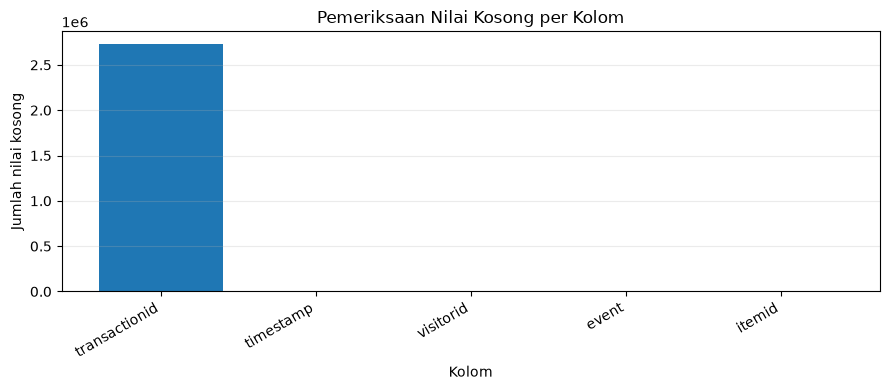

In [3]:
display(pd.read_csv(EVENTS, nrows=5))
print("Kolom:", pd.read_csv(EVENTS, nrows=0).columns.tolist())

n = 0
tmin, tmax = None, None
events = Counter()
missing_counts = Counter()
timestamp_invalid = 0
for ch in pd.read_csv(EVENTS, chunksize=200_000):
    missing_counts.update(ch.isna().sum().to_dict())
    ts_numeric = pd.to_numeric(ch["timestamp"], errors="coerce")
    timestamp_invalid += int(ts_numeric.isna().sum())
    ts = ts_numeric.dropna()
    if len(ts):
        lo, hi = int(ts.min()), int(ts.max())
        tmin = lo if tmin is None else min(tmin, lo)
        tmax = hi if tmax is None else max(tmax, hi)
    n += len(ch)
    events.update(ch["event"].dropna().astype(str).value_counts().to_dict())

print(f"Jumlah baris: {n:,}")
print("Distribusi event:", dict(events))
print("Timestamp awal UTC:", pd.to_datetime(tmin, unit="ms", utc=True))
print("Timestamp akhir UTC:", pd.to_datetime(tmax, unit="ms", utc=True))
print("Timestamp kosong/tidak numerik:", f"{timestamp_invalid:,}")

missing_df = pd.DataFrame({
    "Kolom": list(missing_counts.keys()),
    "Nilai kosong": list(missing_counts.values())
}).sort_values("Nilai kosong", ascending=False)
display(missing_df)

plt.figure(figsize=(9, 4))
plt.bar(missing_df["Kolom"], missing_df["Nilai kosong"])
plt.title("Pemeriksaan Nilai Kosong per Kolom")
plt.xlabel("Kolom")
plt.ylabel("Jumlah nilai kosong")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "eda_missing_values.png", dpi=180)
plt.show()



## 2. Filter training dan testing sesuai tanggal dosen


In [4]:
def ms(date):
    return int(pd.Timestamp(date, tz="UTC").timestamp() * 1000)

TR_START, TR_END = ms("2015-05-11"), ms("2015-07-31")
TE_START, TE_END = ms("2015-07-31"), ms("2015-08-21")

for p in [TRAIN, TEST]:
    if p.exists():
        p.unlink()

counts = {"train": 0, "test": 0}
event_counts = {"train": Counter(), "test": Counter()}
mins, maxs = {"train": None, "test": None}, {"train": None, "test": None}

for ch in pd.read_csv(EVENTS, chunksize=200_000):
    ch["timestamp"] = pd.to_numeric(ch["timestamp"], errors="coerce")
    valid = ch["timestamp"].notna()
    masks = {
        "train": valid & (ch.timestamp >= TR_START) & (ch.timestamp < TR_END),
        "test": valid & (ch.timestamp >= TE_START) & (ch.timestamp < TE_END)
    }
    for name, mask in masks.items():
        part = ch.loc[mask]
        if part.empty:
            continue
        path = TRAIN if name == "train" else TEST
        part.to_csv(path, mode="a", header=not path.exists(), index=False)
        counts[name] += len(part)
        event_counts[name].update(part.event.dropna().astype(str).value_counts().to_dict())
        lo, hi = int(part.timestamp.min()), int(part.timestamp.max())
        mins[name] = lo if mins[name] is None else min(mins[name], lo)
        maxs[name] = hi if maxs[name] is None else max(maxs[name], hi)

for name in ["train", "test"]:
    print("\n", name.upper(), f"{counts[name]:,} baris", dict(event_counts[name]))
    print("Rentang aktual UTC:",
          pd.to_datetime(mins[name], unit="ms", utc=True) if mins[name] else None,
          "sampai",
          pd.to_datetime(maxs[name], unit="ms", utc=True) if maxs[name] else None)
assert counts["train"] and counts["test"], "Salah satu file filter kosong."



 TRAIN 1,732,629 baris {'view': 1676031, 'addtocart': 42494, 'transaction': 14104}
Rentang aktual UTC: 2015-05-11 00:00:01.166000+00:00 sampai 2015-07-30 23:59:59.012000+00:00

 TEST 379,855 baris {'view': 366500, 'addtocart': 10183, 'transaction': 3172}
Rentang aktual UTC: 2015-07-31 00:00:00.789000+00:00 sampai 2015-08-20 23:59:54.835000+00:00


### EDA visual: distribusi event dan tren harian


,event,train,test
0,view,1676031,366500
1,addtocart,42494,10183
2,transaction,14104,3172


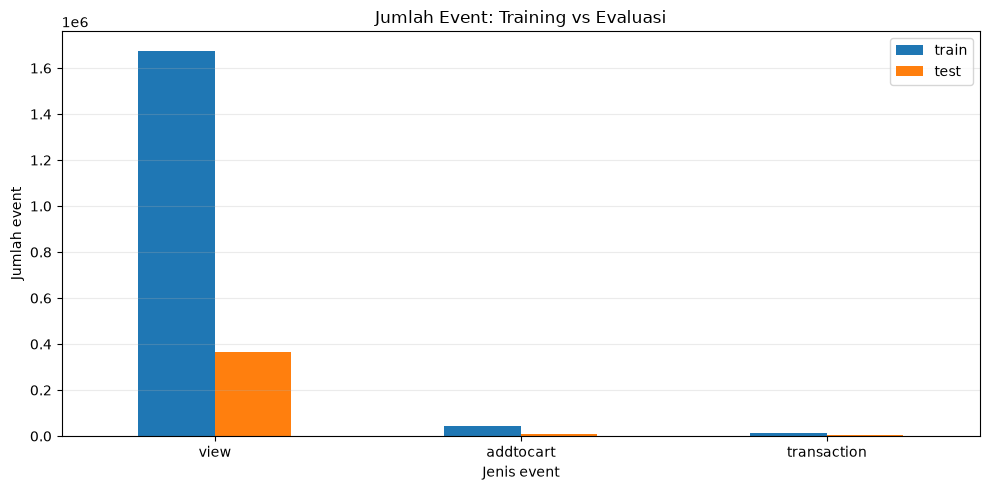

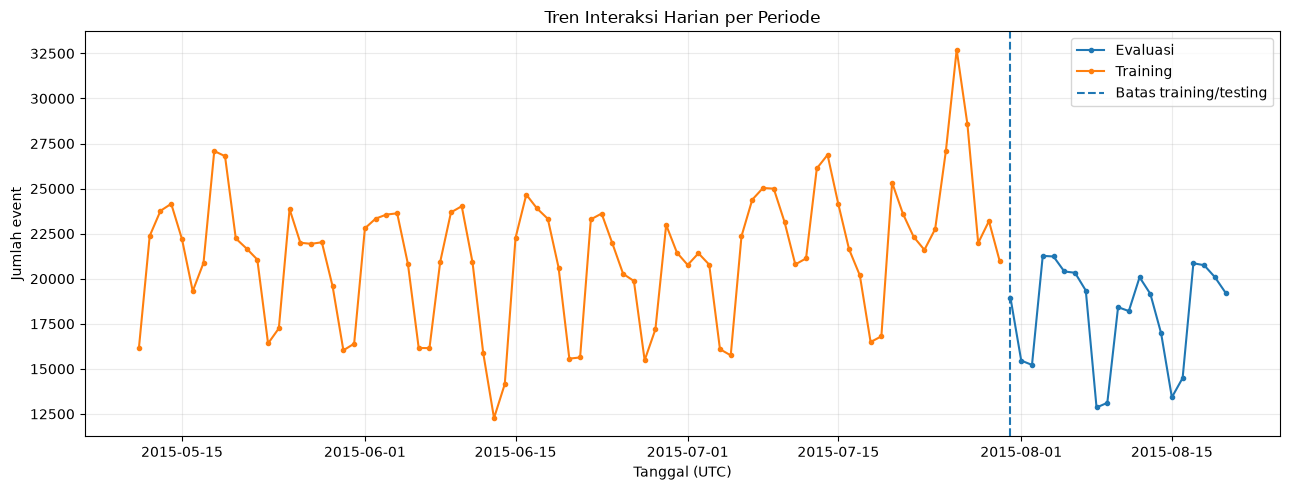

Interpretasi awal: bandingkan volume kedua periode dan periksa apakah ada hari kosong atau lonjakan yang perlu disebutkan dalam laporan.


In [5]:
# A. Perbandingan jenis event antara training dan evaluasi
event_table = pd.DataFrame({
    period: pd.Series(dict(event_counts[period]))
    for period in ["train", "test"]
}).fillna(0).astype(int).fillna(0)

display(event_table.rename_axis("event").reset_index())

ax = event_table.plot(kind="bar", figsize=(10, 5))
ax.set_title("Jumlah Event: Training vs Evaluasi")
ax.set_xlabel("Jenis event")
ax.set_ylabel("Jumlah event")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "eda_event_train_test.png", dpi=180)
plt.show()

# B. Tren volume interaksi harian (dibaca per chunk agar hemat memori)
daily_parts = []
for period, path in [("Training", TRAIN), ("Evaluasi", TEST)]:
    day_counts = Counter()
    for chunk in pd.read_csv(path, usecols=["timestamp"], chunksize=200_000):
        days = pd.to_datetime(chunk["timestamp"], unit="ms", utc=True).dt.strftime("%Y-%m-%d")
        day_counts.update(days.value_counts().to_dict())
    daily_parts.append(pd.DataFrame({
        "tanggal": list(day_counts.keys()),
        "jumlah_event": list(day_counts.values()),
        "periode": period
    }))

daily_df = pd.concat(daily_parts, ignore_index=True)
daily_df["tanggal"] = pd.to_datetime(daily_df["tanggal"], utc=True)
plt.figure(figsize=(13, 5))
for period, part in daily_df.groupby("periode"):
    part = part.sort_values("tanggal")
    plt.plot(part["tanggal"], part["jumlah_event"], marker=".", linewidth=1.5, label=period)
plt.axvline(pd.Timestamp("2015-07-31", tz="UTC"), linestyle="--", label="Batas training/testing")
plt.title("Tren Interaksi Harian per Periode")
plt.xlabel("Tanggal (UTC)")
plt.ylabel("Jumlah event")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "eda_daily_interactions.png", dpi=180)
plt.show()

print("Interpretasi awal: bandingkan volume kedua periode dan periksa apakah ada hari kosong atau lonjakan yang perlu disebutkan dalam laporan.")


## 3. Koneksi langsung ke Neo4j



In [6]:
NEO4J_URI = "bolt://127.0.0.1:7687"
NEO4J_USER = "neo4j"
NEO4J_DB = "neo4j"
NEO4J_PASSWORD = getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))

# Smoke test dengan session.run agar kompatibel dengan Neo4j Python Driver 4.2.1.
with driver.session(database=NEO4J_DB) as session:
    connection_test = session.run("RETURN 1 AS ok").single()
    if not connection_test or connection_test["ok"] != 1:
        raise RuntimeError("Query uji koneksi Neo4j gagal.")

print("Koneksi Neo4j berhasil:", NEO4J_URI, "| database:", NEO4J_DB)


Koneksi Neo4j berhasil: bolt://127.0.0.1:7687 | database: neo4j


### 3.1. Verifikasi koneksi dan data yang benar-benar ada di Neo4j



In [7]:
# Uji koneksi ringan terlebih dahulu.
with driver.session(database=NEO4J_DB) as session:
    ping = session.run("RETURN 1 AS connection_ok").single()
    print("Uji query Cypher:", "BERHASIL" if ping and ping["connection_ok"] == 1 else "GAGAL")

    visitor_record = session.run(
        "MATCH (v:Visitor) RETURN count(v) AS total"
    ).single()
    item_record = session.run(
        "MATCH (i:Item) RETURN count(i) AS total"
    ).single()

    rel_records = list(session.run(
        """
        MATCH (:Visitor)-[r]->(:Item)
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jenis_relasi
        """
    ))

neo4j_visitors = int(visitor_record["total"])
neo4j_items = int(item_record["total"])
neo4j_relations = sum(int(r["jumlah"]) for r in rel_records)

print("\n=== STATUS DATA NEO4J ===")
print(f"Visitor nodes: {neo4j_visitors:,}")
print(f"Item nodes: {neo4j_items:,}")
print(f"Relasi Visitor-Item: {neo4j_relations:,}")

neo4j_rel_df = pd.DataFrame(
    [{"Jenis relasi": r["jenis_relasi"], "Jumlah": int(r["jumlah"])}
     for r in rel_records]
)
display(neo4j_rel_df)

if neo4j_visitors == 0 or neo4j_items == 0 or neo4j_relations == 0:
    print(
        "PERINGATAN: database yang terhubung belum memperlihatkan node/relasi RetailRocket. "
        "Pastikan database yang benar dipilih atau jalankan bagian impor hanya jika database kosong."
    )
else:
    print("Koneksi aktif dan data RetailRocket ditemukan di Neo4j.")


Uji query Cypher: BERHASIL

=== STATUS DATA NEO4J ===
Visitor nodes: 1,407,580
Item nodes: 235,061
Relasi Visitor-Item: 2,756,101


,Jenis relasi,Jumlah
0,ADDED_TO_CART,69332
1,BOUGHT,22457
2,VIEWED,2664312


Koneksi aktif dan data RetailRocket ditemukan di Neo4j.


## 4. Tugas pendahuluan 1.2: `add_friend()` dan `print_friends()`

In [8]:
def add_friend(driver, name, friend_name):
    # session.run kompatibel dengan Neo4j Python Driver 4.x dan 5.x.
    with driver.session(database=NEO4J_DB) as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (f:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(f)
            """,
            name=name, friend_name=friend_name
        ).consume()

def print_friends(driver, name):
    with driver.session(database=NEO4J_DB) as session:
        records = list(session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(f)
            WHERE a.name = $name
            RETURN f.name AS friend_name
            ORDER BY friend_name
            """,
            name=name
        ))
    for rec in records:
        print(rec["friend_name"])

for friend in ["Guinevere", "Lancelot", "Merlin"]:
    add_friend(driver, "Arthur", friend)
print("Teman Arthur:")
print_friends(driver, "Arthur")


Teman Arthur:
Guinevere
Lancelot
Merlin


### Visualisasi contoh `Person`–`KNOWS`

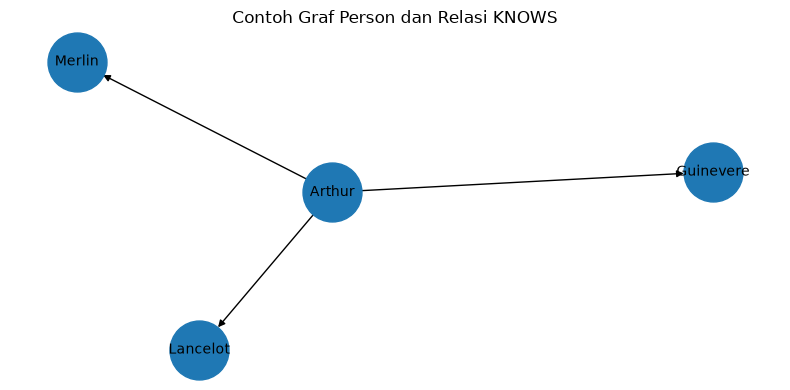

In [9]:
with driver.session(database=NEO4J_DB) as session:
    friend_rows = list(session.run(
        "MATCH (a:Person {name: $name})-[:KNOWS]->(f) RETURN a.name AS person, f.name AS friend ORDER BY friend",
        name="Arthur"
    ))
G_person = nx.DiGraph()
for row in friend_rows:
    G_person.add_edge(row["person"], row["friend"], relationship="KNOWS")
plt.figure(figsize=(8, 4))
pos = nx.spring_layout(G_person, seed=42)
nx.draw_networkx(G_person, pos, node_size=1800, font_size=10, arrows=True)
plt.title("Contoh Graf Person dan Relasi KNOWS")
plt.axis("off")
plt.tight_layout()
plt.savefig(DATA_DIR / "neo4j_person_knows.png", dpi=180)
plt.show()


## 5. Tugas pendahuluan 1.3



In [10]:
IMPORT_FULL_DATASET = False

def execute_write_compat(session, callback, *args):
    # execute_write untuk driver baru, write_transaction untuk driver lama.
    if hasattr(session, "execute_write"):
        return session.execute_write(callback, *args)
    return session.write_transaction(callback, *args)

def import_event_batch(tx, batch):
    tx.run(
        """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
            MERGE (v)-[r:VIEWED {eventId: row.event_id}]->(i)
            SET r.timestamp = row.timestamp
        )
        FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
            MERGE (v)-[r:ADDED_TO_CART {eventId: row.event_id}]->(i)
            SET r.timestamp = row.timestamp
        )
        FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
            MERGE (v)-[r:BOUGHT {eventId: row.event_id}]->(i)
            SET r.timestamp = row.timestamp,
                r.transactionId = row.transactionid
        )
        """,
        batch=batch
    ).consume()

if IMPORT_FULL_DATASET:
    batch_size = 5000
    offset = 0
    with driver.session(database=NEO4J_DB) as session:
        for chunk in pd.read_csv(EVENTS, chunksize=batch_size):
            for col in ["visitorid", "itemid", "timestamp"]:
                chunk[col] = pd.to_numeric(chunk[col], errors="raise").astype("int64")
            chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
            chunk["event_id"] = np.arange(offset, offset + len(chunk), dtype=np.int64)
            offset += len(chunk)
            execute_write_compat(session, import_event_batch, chunk.to_dict("records"))
            print(f"Baris diproses: {offset:,}")
    print("Impor selesai.")
else:
    print("Impor penuh dilewati: database RetailRocket kamu sudah pernah diisi.")


Impor penuh dilewati: database RetailRocket kamu sudah pernah diisi.


## 6. Soal 2.1 nomor 3: komposisi subgraph training via Python API Neo4j



In [11]:
with driver.session(database=NEO4J_DB) as session:
    stats = session.run(
        """
        MATCH (v:Visitor)-[r]->(i:Item)
        WHERE r.timestamp >= $start AND r.timestamp < $end
        RETURN count(DISTINCT v) AS visitors,
               count(DISTINCT i) AS items,
               count(r) AS relationships
        """,
        start=TR_START, end=TR_END
    ).single()
    print("Visitor unik:", f"{stats['visitors']:,}")
    print("Item unik:", f"{stats['items']:,}")
    print("Relasi:", f"{stats['relationships']:,}")
    print("Relasi per jenis:")
    rows = session.run(
        """
        MATCH (:Visitor)-[r]->(:Item)
        WHERE r.timestamp >= $start AND r.timestamp < $end
        RETURN type(r) AS kind, count(r) AS total
        ORDER BY kind
        """,
        start=TR_START, end=TR_END
    )
    for row in rows:
        print(row["kind"], f"{row['total']:,}")


Visitor unik: 882,707
Item unik: 192,332
Relasi: 1,732,629
Relasi per jenis:
ADDED_TO_CART 42,494
BOUGHT 14,104
VIEWED 1,676,031


### Visualisasi komposisi subgraph


,Komponen,Jumlah
0,Visitor unik,882707
1,Item unik,192332
2,Relasi interaksi,1732629


,jenis_relasi,jumlah
0,ADDED_TO_CART,42494
1,BOUGHT,14104
2,VIEWED,1676031


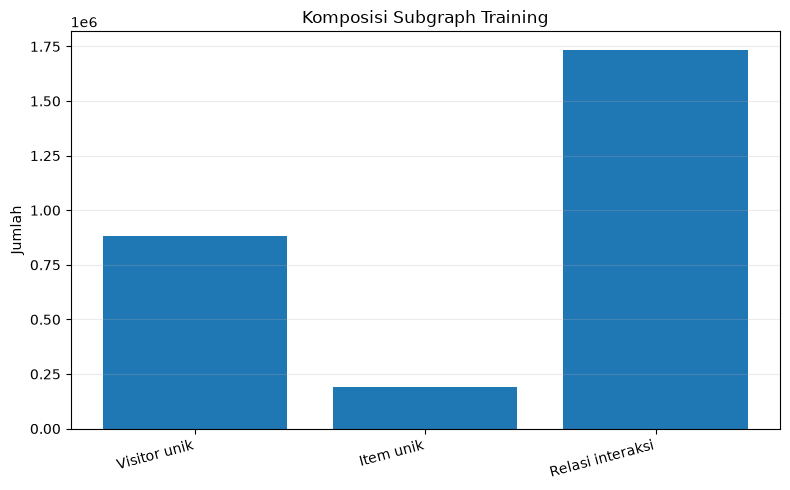

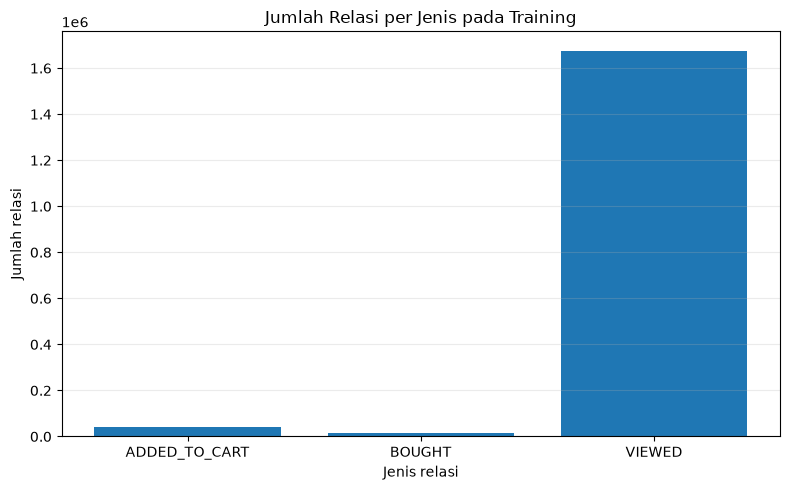

In [12]:
with driver.session(database=NEO4J_DB) as session:
    type_rows = [dict(r) for r in session.run(
        """
        MATCH (:Visitor)-[r]->(:Item)
        WHERE r.timestamp >= $start AND r.timestamp < $end
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jenis_relasi
        """,
        start=TR_START, end=TR_END
    )]
type_df = pd.DataFrame(type_rows)
node_edge_df = pd.DataFrame({
    "Komponen": ["Visitor unik", "Item unik", "Relasi interaksi"],
    "Jumlah": [int(stats["visitors"]), int(stats["items"]), int(stats["relationships"])]
})
display(node_edge_df)
display(type_df)

plt.figure(figsize=(8, 5))
plt.bar(node_edge_df["Komponen"], node_edge_df["Jumlah"])
plt.title("Komposisi Subgraph Training")
plt.ylabel("Jumlah")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "subgraph_composition.png", dpi=180)
plt.show()

if not type_df.empty:
    plt.figure(figsize=(8, 5))
    plt.bar(type_df["jenis_relasi"], type_df["jumlah"])
    plt.title("Jumlah Relasi per Jenis pada Training")
    plt.xlabel("Jenis relasi")
    plt.ylabel("Jumlah relasi")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(DATA_DIR / "subgraph_relationship_types.png", dpi=180)
    plt.show()


## 7. Soal 2.1 nomor 4–5: VSM user-item dan item-user


In [13]:
df = pd.read_csv(
    TRAIN, usecols=["visitorid", "itemid", "event"],
    dtype={"visitorid":"int64", "itemid":"int64", "event":"string"}
)
df["event"] = df.event.str.lower().str.strip()
df["weight"] = df.event.map({"view":1.0, "addtocart":2.0, "transaction":3.0})
df = df.dropna(subset=["weight"]).copy()

uc, user_ids = pd.factorize(df.visitorid, sort=True)
ic, item_ids = pd.factorize(df.itemid, sort=True)
X = coo_matrix(
    (df.weight.to_numpy(np.float32), (uc, ic)),
    shape=(len(user_ids), len(item_ids)), dtype=np.float32
).tocsr()
X.sum_duplicates()
X.eliminate_zeros()
X.sort_indices()

save_npz(DATA_DIR / "vsm_user_item.npz", X)
save_npz(DATA_DIR / "vsm_item_user.npz", X.T.tocsr())
np.save(DATA_DIR / "vsm_user_ids.npy", np.asarray(user_ids, dtype=np.int64))
np.save(DATA_DIR / "vsm_item_ids.npy", np.asarray(item_ids, dtype=np.int64))

users, items = X.shape
density = X.nnz / (users * items) * 100
print("Shape user-item:", X.shape)
print("Shape item-user:", X.T.shape)
print("Pasangan nonnol:", f"{X.nnz:,}")
print(f"Densitas: {density:.8f}%")
print(f"Sparsity: {100-density:.8f}%")


Shape user-item: (882707, 192332)
Shape item-user: (192332, 882707)
Pasangan nonnol: 1,345,274
Densitas: 0.00079240%
Sparsity: 99.99920760%


### VSM diagnostics dan visualisasi sparsity



,Ukuran,Jumlah entitas,Rata-rata interaksi unik,Median interaksi unik,Maksimum interaksi unik
0,User,882707,1.524032,1.0,2460
1,Item,192332,6.994541,2.0,1669


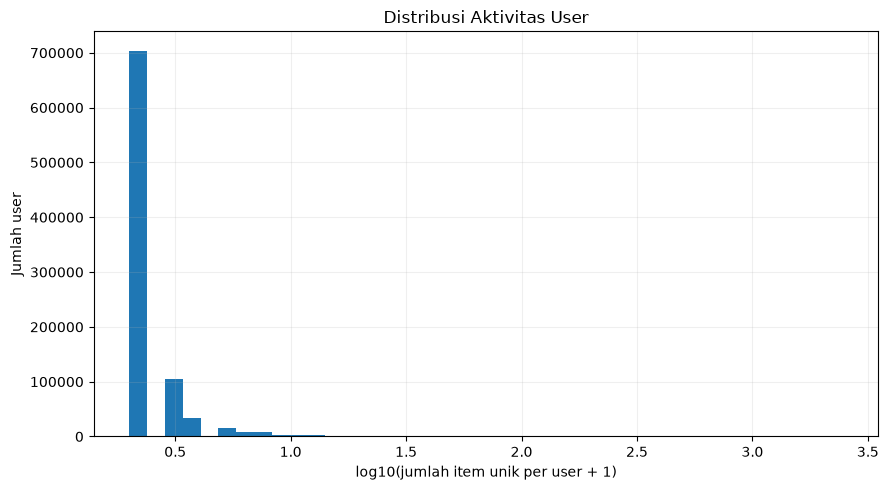

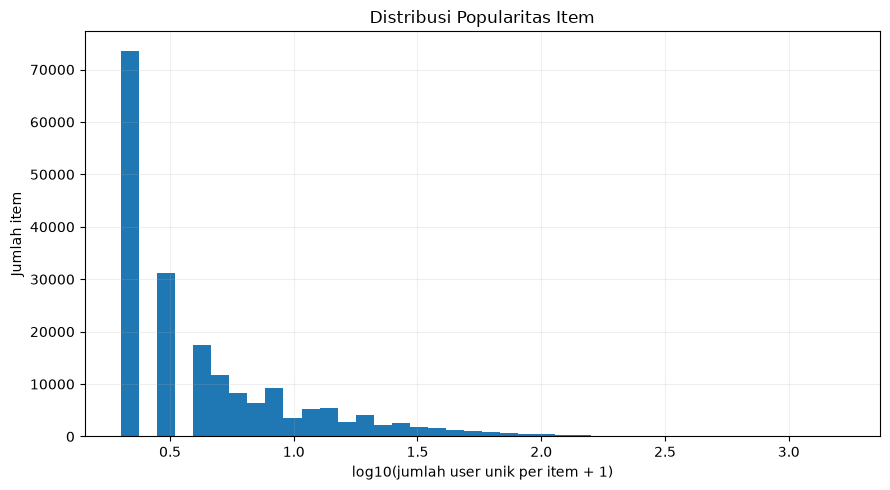

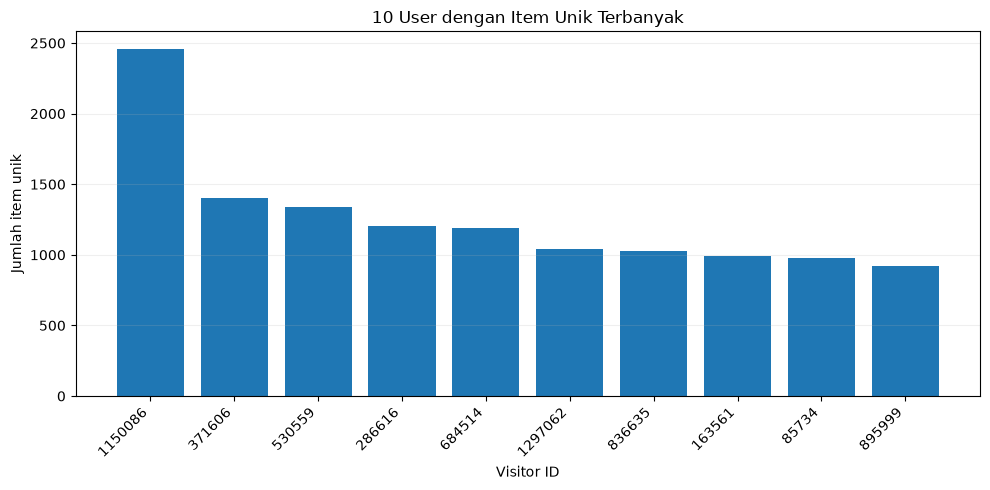

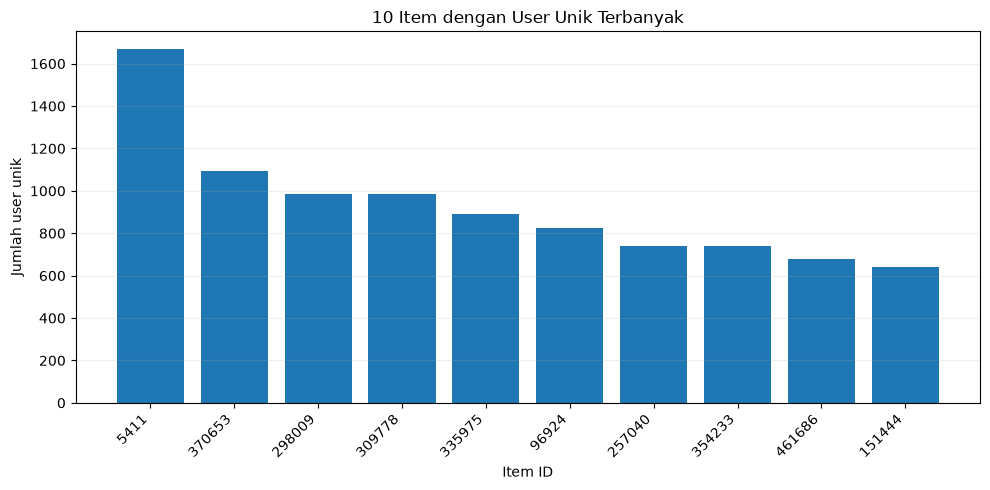

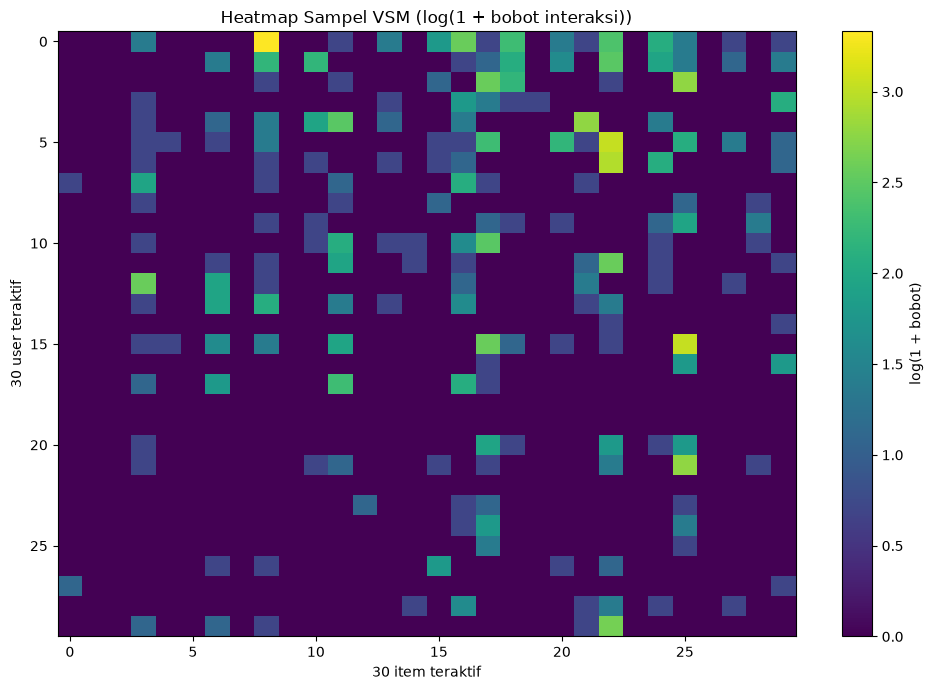

Matriks berisi 1,345,274 nilai nonnol dari 169,772,802,724 kemungkinan pasangan user-item.
Sparsity 99.999208% menunjukkan sebagian besar pasangan user-item tidak memiliki interaksi.


In [14]:
user_activity = np.diff(X.indptr)
item_activity = np.diff(X.tocsc().indptr)

activity_summary = pd.DataFrame({
    "Ukuran": ["User", "Item"],
    "Jumlah entitas": [len(user_activity), len(item_activity)],
    "Rata-rata interaksi unik": [float(user_activity.mean()), float(item_activity.mean())],
    "Median interaksi unik": [float(np.median(user_activity)), float(np.median(item_activity))],
    "Maksimum interaksi unik": [int(user_activity.max()), int(item_activity.max())]
})
display(activity_summary)

plt.figure(figsize=(9, 5))
plt.hist(np.log10(user_activity + 1), bins=40)
plt.title("Distribusi Aktivitas User")
plt.xlabel("log10(jumlah item unik per user + 1)")
plt.ylabel("Jumlah user")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(DATA_DIR / "vsm_user_activity_distribution.png", dpi=180)
plt.show()

plt.figure(figsize=(9, 5))
plt.hist(np.log10(item_activity + 1), bins=40)
plt.title("Distribusi Popularitas Item")
plt.xlabel("log10(jumlah user unik per item + 1)")
plt.ylabel("Jumlah item")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(DATA_DIR / "vsm_item_activity_distribution.png", dpi=180)
plt.show()

top_u = np.argsort(user_activity)[-10:][::-1]
plt.figure(figsize=(10, 5))
plt.bar([str(int(user_ids[j])) for j in top_u], user_activity[top_u])
plt.title("10 User dengan Item Unik Terbanyak")
plt.xlabel("Visitor ID")
plt.ylabel("Jumlah item unik")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(DATA_DIR / "vsm_top_users.png", dpi=180)
plt.show()

top_i = np.argsort(item_activity)[-10:][::-1]
plt.figure(figsize=(10, 5))
plt.bar([str(int(item_ids[j])) for j in top_i], item_activity[top_i])
plt.title("10 Item dengan User Unik Terbanyak")
plt.xlabel("Item ID")
plt.ylabel("Jumlah user unik")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(DATA_DIR / "vsm_top_items.png", dpi=180)
plt.show()

# Heatmap sampel: user dan item paling aktif.
u_sample = np.argsort(user_activity)[-30:][::-1]
i_sample = np.argsort(item_activity)[-30:][::-1]
sample_matrix = X[u_sample, :][:, i_sample].toarray()
plt.figure(figsize=(10, 7))
plt.imshow(np.log1p(sample_matrix), aspect="auto", interpolation="nearest")
plt.title("Heatmap Sampel VSM (log(1 + bobot interaksi))")
plt.xlabel("30 item teraktif")
plt.ylabel("30 user teraktif")
plt.colorbar(label="log(1 + bobot)")
plt.tight_layout()
plt.savefig(DATA_DIR / "vsm_sparsity_heatmap.png", dpi=180)
plt.show()

print(f"Matriks berisi {X.nnz:,} nilai nonnol dari {X.shape[0] * X.shape[1]:,} kemungkinan pasangan user-item.")
print(f"Sparsity {100 - (X.nnz / (X.shape[0] * X.shape[1]) * 100):.6f}% menunjukkan sebagian besar pasangan user-item tidak memiliki interaksi.")


### Plot NetworkX sampel graf bipartit

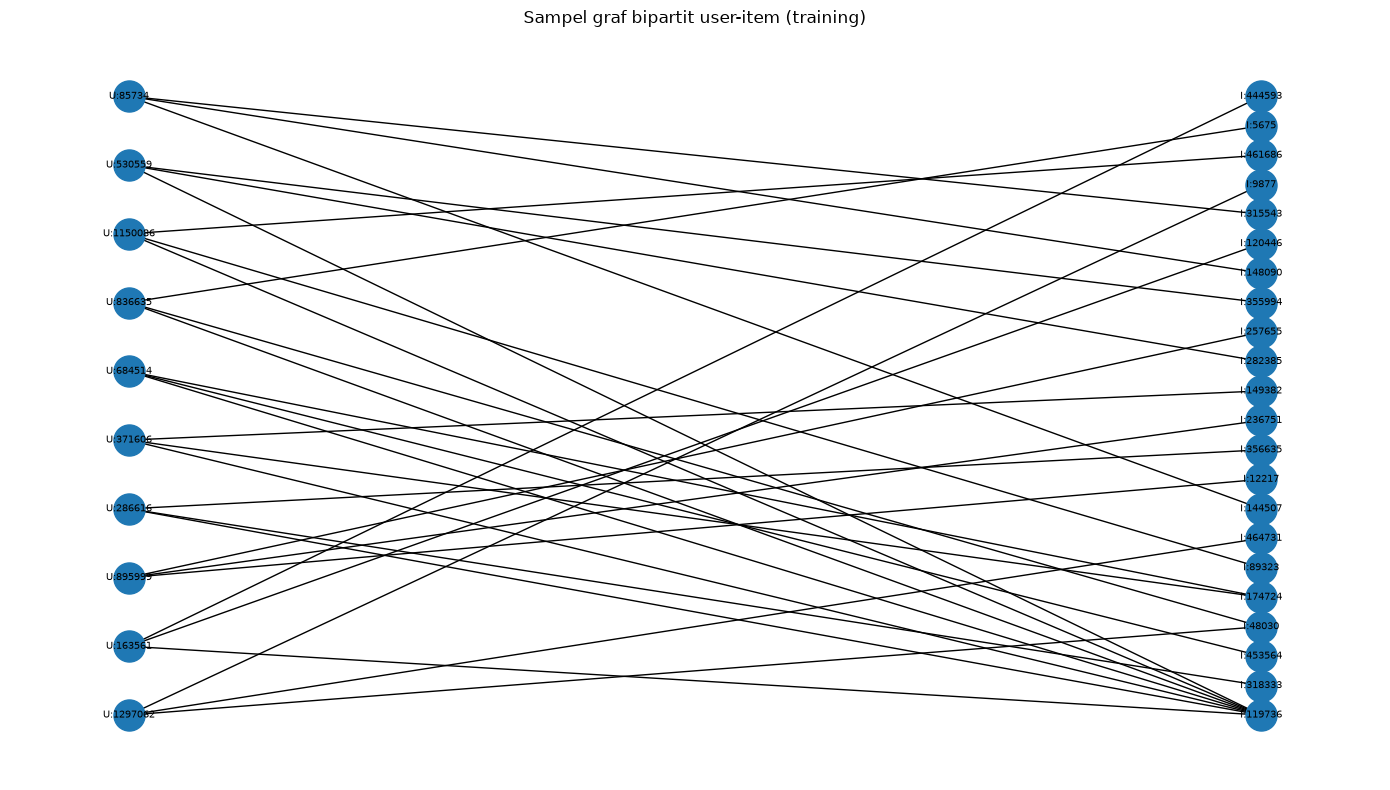

In [15]:
activity = np.diff(X.indptr)
top_users = np.argsort(activity)[-10:][::-1]
G = nx.Graph()
user_nodes = []
for u in top_users:
    un = f"U:{int(user_ids[u])}"
    user_nodes.append(un)
    G.add_node(un, bipartite=0)
    row = X.getrow(u)
    for j in np.argsort(row.data)[::-1][:3]:
        it = f"I:{int(item_ids[row.indices[j]])}"
        G.add_node(it, bipartite=1)
        G.add_edge(un, it, weight=float(row.data[j]))
pos = nx.bipartite_layout(G, user_nodes, align="vertical")
plt.figure(figsize=(14, 8))
nx.draw_networkx(G, pos, node_size=500, font_size=7, with_labels=True)
plt.title("Sampel graf bipartit user-item (training)")
plt.axis("off")
plt.tight_layout()
plt.savefig(DATA_DIR / "vsm_network_sample.png", dpi=180)
plt.show()


### Plot NetworkX item-user: perspektif item


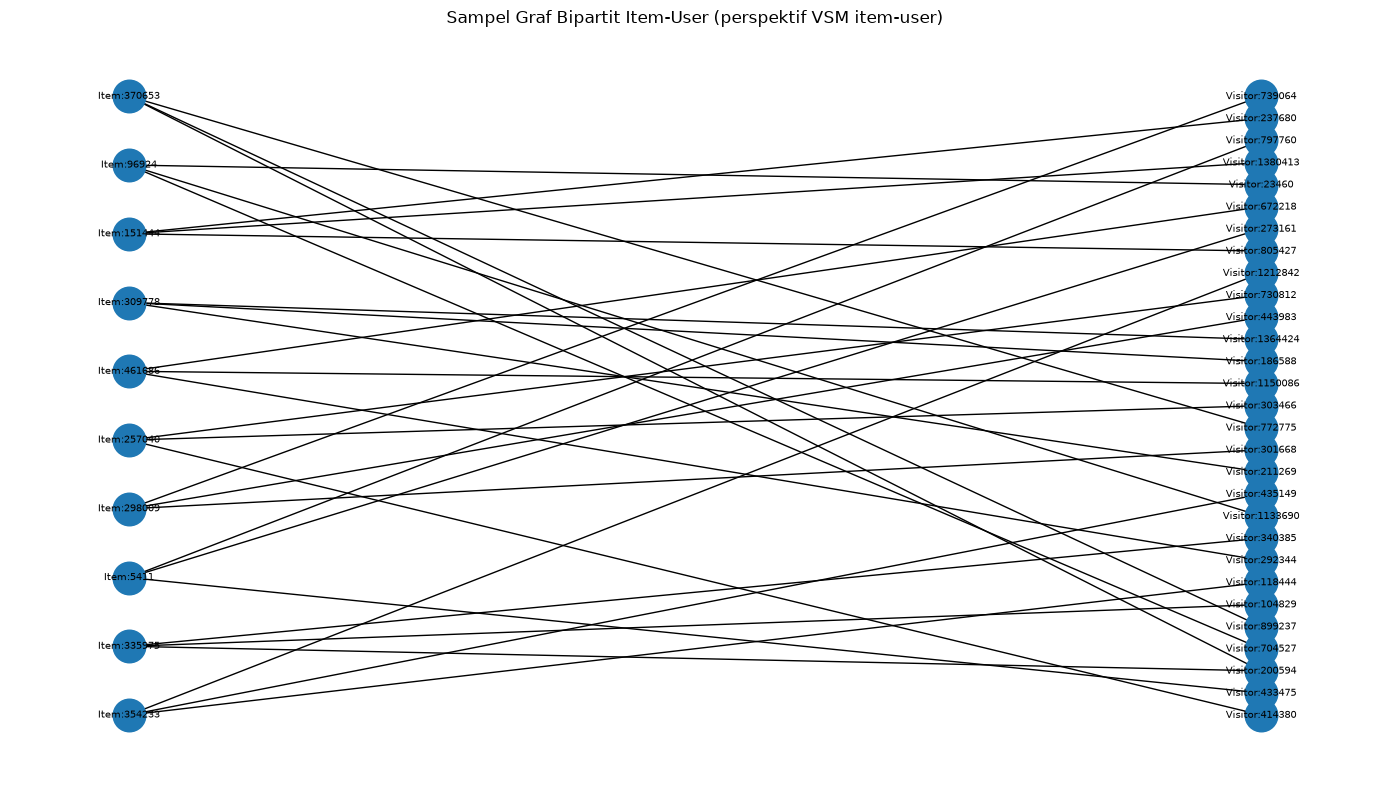

In [16]:
X_item_user_plot = X.T.tocsr()
top_items_plot = np.argsort(item_activity)[-10:][::-1]

G_item_centered = nx.Graph()
item_nodes_plot = []

for item_idx in top_items_plot:
    item_node = f"Item:{int(item_ids[item_idx])}"
    item_nodes_plot.append(item_node)
    G_item_centered.add_node(item_node, bipartite=0)

    user_row = X_item_user_plot.getrow(item_idx)
    if user_row.nnz == 0:
        continue

    selected_users = np.argsort(user_row.data)[::-1][:3]
    for j in selected_users:
        user_idx = int(user_row.indices[j])
        user_node = f"Visitor:{int(user_ids[user_idx])}"
        G_item_centered.add_node(user_node, bipartite=1)
        G_item_centered.add_edge(
            item_node, user_node, weight=float(user_row.data[j])
        )

pos_item = nx.bipartite_layout(
    G_item_centered, item_nodes_plot, align="vertical"
)
plt.figure(figsize=(14, 8))
nx.draw_networkx(
    G_item_centered, pos_item,
    node_size=550, font_size=7, with_labels=True
)
plt.title("Sampel Graf Bipartit Item-User (perspektif VSM item-user)")
plt.axis("off")
plt.tight_layout()
plt.savefig(DATA_DIR / "vsm_item_user_network_sample.png", dpi=180)
plt.show()


## 8. Soal 2.1 nomor 6: perbandingan proyeksi



In [17]:
user_pairs = users * (users - 1) // 2
item_pairs = items * (items - 1) // 2
print(f"Pasangan potensial user: {user_pairs:,}")
print(f"Pasangan potensial item: {item_pairs:,}")
print(f"Rasio user/item: {user_pairs / max(item_pairs, 1):.2f}x")


Pasangan potensial user: 389,585,382,571
Pasangan potensial item: 18,495,702,946
Rasio user/item: 21.06x


### Visualisasi perbandingan ukuran proyeksi

,Proyeksi,Node,Pasangan potensial
0,User-user,882707,389585382571
1,Item-item,192332,18495702946


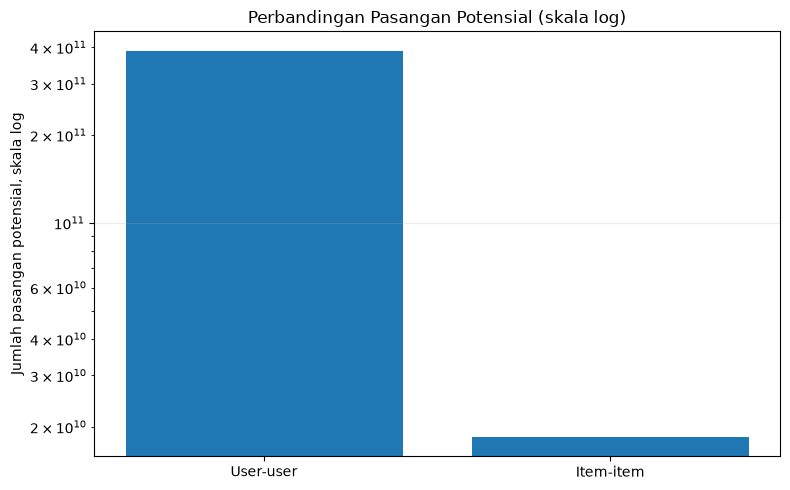

Interpretasi: proyeksi dengan lebih sedikit pasangan potensial lebih hemat untuk pencarian similarity. Keputusan akhir juga mempertimbangkan tujuan rekomendasi item.


In [18]:
projection_df = pd.DataFrame({
    "Proyeksi": ["User-user", "Item-item"],
    "Node": [users, items],
    "Pasangan potensial": [user_pairs, item_pairs]
})
display(projection_df)

plt.figure(figsize=(8, 5))
plt.bar(projection_df["Proyeksi"], projection_df["Pasangan potensial"])
plt.yscale("log")
plt.title("Perbandingan Pasangan Potensial (skala log)")
plt.ylabel("Jumlah pasangan potensial, skala log")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "projection_pair_comparison.png", dpi=180)
plt.show()

print("Interpretasi: proyeksi dengan lebih sedikit pasangan potensial lebih hemat untuk pencarian similarity. Keputusan akhir juga mempertimbangkan tujuan rekomendasi item.")


## 9. Soal 2.1 nomor 7: cosine similarity item


In [19]:
Xi = X.T.tocsr()
degrees = np.diff(Xi.indptr)
eligible = np.flatnonzero(degrees >= 10)
if len(eligible) == 0:
    raise ValueError("Tidak ada item yang memiliki minimal 10 user dalam training.")

rng = np.random.default_rng(42)
ref_idx = int(rng.choice(eligible))
ref_id = int(item_ids[ref_idx])
ref_vec = Xi.getrow(ref_idx)

dots = Xi.dot(ref_vec.T).toarray().ravel()
norms = np.sqrt(np.asarray(Xi.multiply(Xi).sum(axis=1)).ravel())
denom = norms * norms[ref_idx]
sim = np.divide(dots, denom, out=np.zeros_like(dots, dtype=float), where=denom > 0)

cand = np.flatnonzero(dots > 0)
cand = cand[cand != ref_idx]
sim_df = pd.DataFrame({
    "reference_item_id": ref_id,
    "similar_item_id": item_ids[cand].astype(np.int64),
    "similarity": sim[cand]
}).sort_values(["similarity", "similar_item_id"], ascending=[False, True]).reset_index(drop=True)
sim_df.to_csv(DATA_DIR / "item_similarity_candidates.csv", index=False)
print("Item acuan:", ref_id)
print("Jumlah user item acuan:", int(degrees[ref_idx]))
print("Kandidat similarity:", len(sim_df))
display(sim_df.head(5))


Item acuan: 42874
Jumlah user item acuan: 21
Kandidat similarity: 745


,reference_item_id,similar_item_id,similarity
0,42874,317192,0.775165
1,42874,16370,0.709550
2,42874,28161,0.680847
3,42874,275580,0.515896
4,42874,133250,0.450988


### Visualisasi hasil cosine similarity

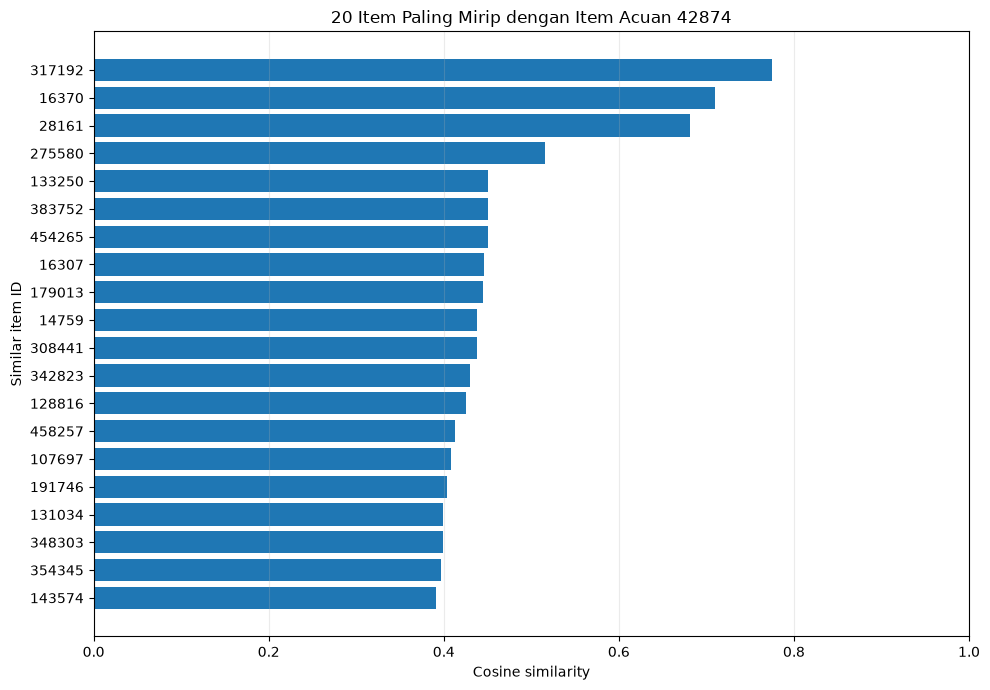

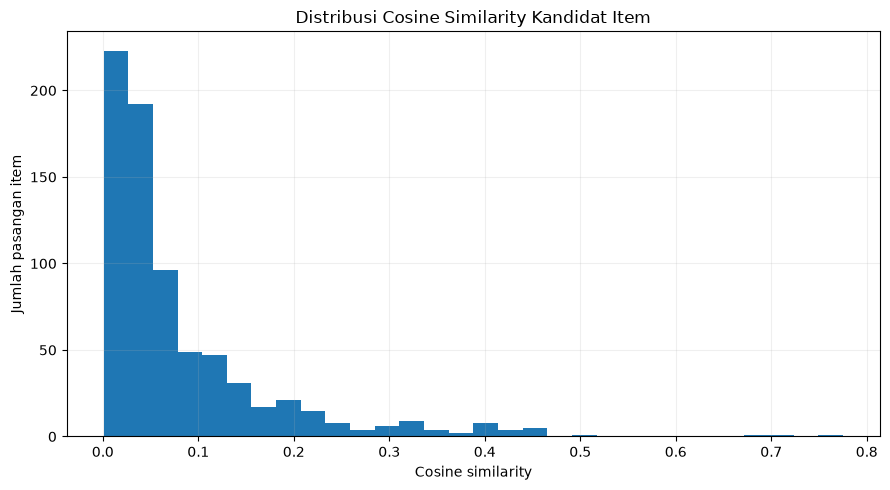

Skor cosine similarity berada pada rentang 0–1 untuk vektor interaksi nonnegatif.
Nilai lebih tinggi menunjukkan pola user yang berinteraksi dengan kedua item cenderung lebih serupa.


In [20]:
top20_sim = sim_df.head(20).sort_values("similarity", ascending=True)
plt.figure(figsize=(10, 7))
plt.barh(top20_sim["similar_item_id"].astype(str), top20_sim["similarity"])
plt.title(f"20 Item Paling Mirip dengan Item Acuan {ref_id}")
plt.xlabel("Cosine similarity")
plt.ylabel("Similar item ID")
plt.xlim(0, 1.0)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "item_similarity_top20.png", dpi=180)
plt.show()

plt.figure(figsize=(9, 5))
plt.hist(sim_df["similarity"], bins=30)
plt.title("Distribusi Cosine Similarity Kandidat Item")
plt.xlabel("Cosine similarity")
plt.ylabel("Jumlah pasangan item")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(DATA_DIR / "item_similarity_distribution.png", dpi=180)
plt.show()

print("Skor cosine similarity berada pada rentang 0–1 untuk vektor interaksi nonnegatif.")
print("Nilai lebih tinggi menunjukkan pola user yang berinteraksi dengan kedua item cenderung lebih serupa.")


## 10. Soal 2.1 nomor 7(b)–8: simpan similarity, query Cypher, dan graf sebelum/sesudah


### Simpan similarity ke Neo4j


In [21]:
rows = sim_df.to_dict("records")

def write_sim_batch(tx, batch):
    tx.run(
        """
        UNWIND $rows AS row
        MERGE (b:Item {itemId: toInteger(row.reference_item_id)})
        MERGE (c:Item {itemId: toInteger(row.similar_item_id)})
        MERGE (b)-[r:SIMILAR_TO]->(c)
        SET r.similarity = toFloat(row.similarity),
            r.method = 'cosine',
            r.data_split = 'training'
        """,
        rows=batch
    ).consume()

def execute_write_compat(session, callback, *args):
    # execute_write pada driver baru; write_transaction pada driver lama.
    if hasattr(session, "execute_write"):
        return session.execute_write(callback, *args)
    return session.write_transaction(callback, *args)

with driver.session(database=NEO4J_DB) as session:
    session.run(
        "MATCH (b:Item {itemId: $id})-[r:SIMILAR_TO]->() DELETE r",
        id=ref_id
    ).consume()
    for start in range(0, len(rows), 1000):
        execute_write_compat(session, write_sim_batch, rows[start:start+1000])
print("Similarity tersimpan untuk item:", ref_id)


Similarity tersimpan untuk item: 42874


### Query Cypher Top 5

In [22]:
with driver.session(database=NEO4J_DB) as session:
    records = list(session.run(
        """
        MATCH (b:Item {itemId: $id})-[r:SIMILAR_TO]->(c:Item)
        RETURN b.itemId AS item_acuan, c.itemId AS item_mirip,
               r.similarity AS similarity
        ORDER BY similarity DESC LIMIT 5
        """,
        id=ref_id
    ))
top5 = pd.DataFrame([dict(r) for r in records])
display(top5)


,item_acuan,item_mirip,similarity
0,42874,317192,0.775165
1,42874,16370,0.709550
2,42874,28161,0.680847
3,42874,275580,0.515896
4,42874,454265,0.450988


### Graf sebelum/sesudah similarity (NetworkX)


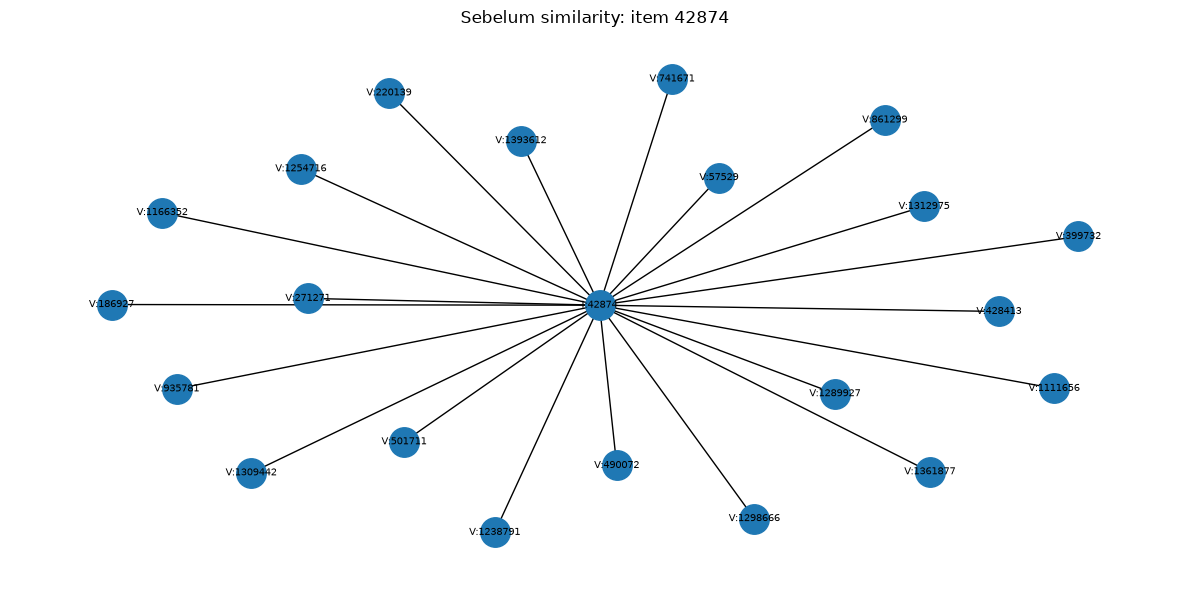

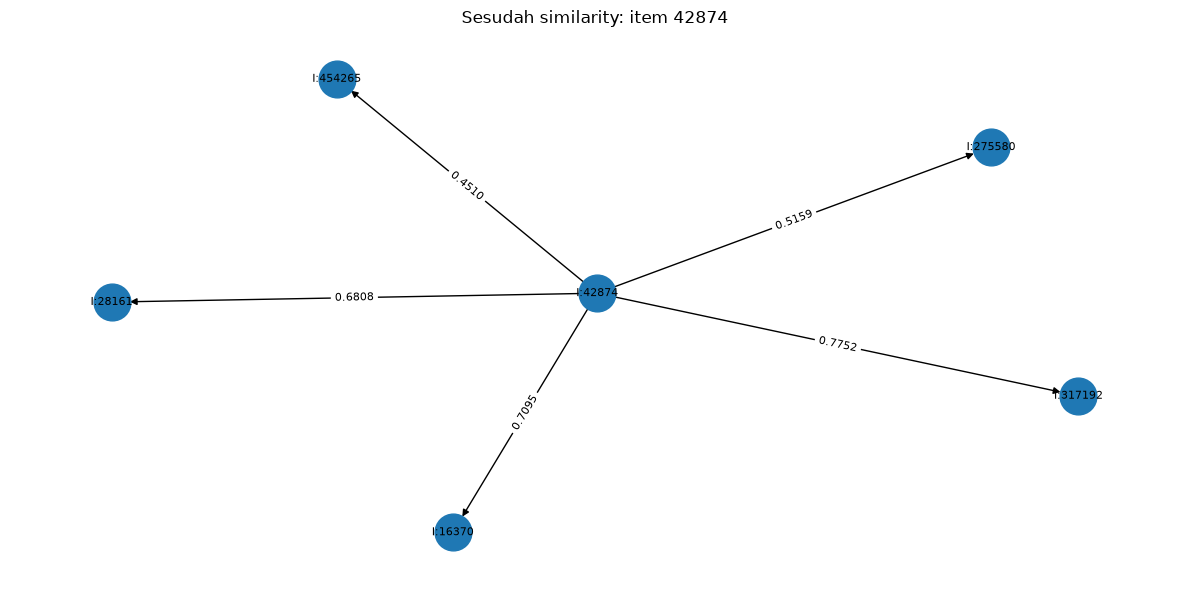

In [23]:
with driver.session(database=NEO4J_DB) as session:
    before = list(session.run(
        """
        MATCH (v:Visitor)-[r]->(i:Item {itemId: $id})
        WHERE r.timestamp >= $start AND r.timestamp < $end
        RETURN v.visitorId AS visitor, type(r) AS event, i.itemId AS item
        LIMIT 30
        """,
        id=ref_id, start=TR_START, end=TR_END
    ))

Gb = nx.Graph()
for r in before:
    u, it = f"V:{r['visitor']}", f"I:{r['item']}"
    Gb.add_edge(u, it, event=r["event"])
plt.figure(figsize=(12, 6))
if Gb.number_of_edges():
    nx.draw_networkx(Gb, nx.spring_layout(Gb, seed=42), node_size=450, font_size=7)
else:
    plt.text(.5, .5, "Tidak ada relasi untuk item acuan pada periode training", ha="center")
plt.title(f"Sebelum similarity: item {ref_id}")
plt.axis("off")
plt.tight_layout()
plt.savefig(DATA_DIR / "graf_sebelum_similarity.png", dpi=180)
plt.show()

Ga = nx.DiGraph()
for r in records:
    Ga.add_edge(f"I:{r['item_acuan']}", f"I:{r['item_mirip']}", similarity=float(r["similarity"]))
plt.figure(figsize=(12, 6))
if Ga.number_of_edges():
    pos = nx.spring_layout(Ga, seed=42)
    nx.draw_networkx(Ga, pos, node_size=700, font_size=8, arrows=True)
    labels = {(u,v): f"{d['similarity']:.4f}" for u,v,d in Ga.edges(data=True)}
    nx.draw_networkx_edge_labels(Ga, pos, edge_labels=labels, font_size=8)
plt.title(f"Sesudah similarity: item {ref_id}")
plt.axis("off")
plt.tight_layout()
plt.savefig(DATA_DIR / "graf_sesudah_similarity.png", dpi=180)
plt.show()


## 11. Soal 2.2: KNN (`k=5`), rekomendasi, Hit@5, dan NDCG@5


In [24]:
test_df = pd.read_csv(
    TEST, usecols=["visitorid", "itemid", "event"],
    dtype={"visitorid":"int64", "itemid":"int64", "event":"string"}
)
test_df["event"] = test_df.event.str.lower().str.strip()
test_df = test_df[test_df.event.isin(["view", "addtocart", "transaction"])]

ru = test_df.visitorid.to_numpy(dtype=np.int64)
ri = test_df.itemid.to_numpy(dtype=np.int64)
ui = np.searchsorted(user_ids, ru)
ii = np.searchsorted(item_ids, ri)
um = np.zeros(len(ru), dtype=bool)
im = np.zeros(len(ri), dtype=bool)
uok, iok = ui < len(user_ids), ii < len(item_ids)
um[uok] = user_ids[ui[uok]] == ru[uok]
im[iok] = item_ids[ii[iok]] == ri[iok]
known = um & im
ui, ii = ui[known], ii[known]

train_rows = np.repeat(np.arange(X.shape[0], dtype=np.int64), np.diff(X.indptr))
train_keys = train_rows * np.int64(X.shape[1]) + X.indices.astype(np.int64)
test_keys = ui.astype(np.int64) * np.int64(X.shape[1]) + ii.astype(np.int64)
p = np.searchsorted(train_keys, test_keys)
inrange = p < len(train_keys)
seen = np.zeros(len(p), dtype=bool)
seen[inrange] = train_keys[p[inrange]] == test_keys[inrange]
unseen = ~seen
eligible_users = np.unique(ui[unseen])
if len(eligible_users) == 0:
    raise ValueError("Tidak ada user yang memenuhi kriteria evaluasi.")

SEED_KNN, K, TOP_N, MAX_ATTEMPTS = 42, 5, 5, 200
rng = np.random.default_rng(SEED_KNN)
order_users = rng.permutation(eligible_users)
user_norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=1)).ravel())
chosen = None

for attempt, target in enumerate(order_users[:MAX_ATTEMPTS], start=1):
    target = int(target)
    vec = X.getrow(target)
    dot = X.dot(vec.T).toarray().ravel()
    den = user_norms * user_norms[target]
    sims = np.divide(dot, den, out=np.zeros_like(dot, dtype=float), where=den > 0)
    sims[target] = -1.0
    possible = np.flatnonzero(sims > 0)
    if len(possible) < K:
        continue
    order = np.lexsort((user_ids[possible], -sims[possible]))
    neigh = possible[order[:K]]
    ns = sims[neigh]
    scores = np.asarray(X[neigh].T.dot(ns)).ravel()
    scores[vec.indices] = -np.inf
    candidates = np.flatnonzero(np.isfinite(scores) & (scores > 0))
    if len(candidates) < TOP_N:
        continue
    ranked = candidates[np.lexsort((item_ids[candidates], -scores[candidates]))[:TOP_N]]
    relevant = np.unique(ii[unseen & (ui == target)])
    chosen = dict(target=target, neigh=neigh, ns=ns, scores=scores,
                  ranked=ranked, relevant=relevant, attempt=attempt)
    break

if chosen is None:
    raise RuntimeError("Tidak menemukan user yang menghasilkan minimal lima kandidat dalam 200 percobaan.")

target = chosen["target"]
relevant_set = set(chosen["relevant"].tolist())
neighbors_df = pd.DataFrame({
    "neighbor_user_id": user_ids[chosen["neigh"]],
    "cosine_similarity": chosen["ns"]
})
recommendations_df = pd.DataFrame({
    "rank": np.arange(1, len(chosen["ranked"])+1),
    "item_id": item_ids[chosen["ranked"]],
    "score": chosen["scores"][chosen["ranked"]]
})
neighbors_df.to_csv(DATA_DIR / "knn_neighbors.csv", index=False)
recommendations_df.to_csv(DATA_DIR / "knn_recommendations.csv", index=False)

print("Seed:", SEED_KNN, "| Percobaan:", chosen["attempt"])
print("User target:", int(user_ids[target]))
print("Item relevan testing:", item_ids[chosen["relevant"]].tolist())
print("\nLima tetangga:")
display(neighbors_df)
print("\nTiga rekomendasi:")
display(recommendations_df.head(3))
print("\nTop 5 evaluasi:")
display(recommendations_df)


Seed: 42 | Percobaan: 24
User target: 335902
Item relevan testing: [268883]

Lima tetangga:


,neighbor_user_id,cosine_similarity
0,1230943,0.707107
1,259962,0.577350
2,428608,0.500000
3,139139,0.196116
4,340817,0.176777



Tiga rekomendasi:


,rank,item_id,score
0,1,69917,0.754127
1,2,273604,0.577350
2,3,323676,0.549670



Top 5 evaluasi:


,rank,item_id,score
0,1,69917,0.754127
1,2,273604,0.577350
2,3,323676,0.549670
3,4,404920,0.500000
4,5,193249,0.353553


### Visualisasi hasil KNN

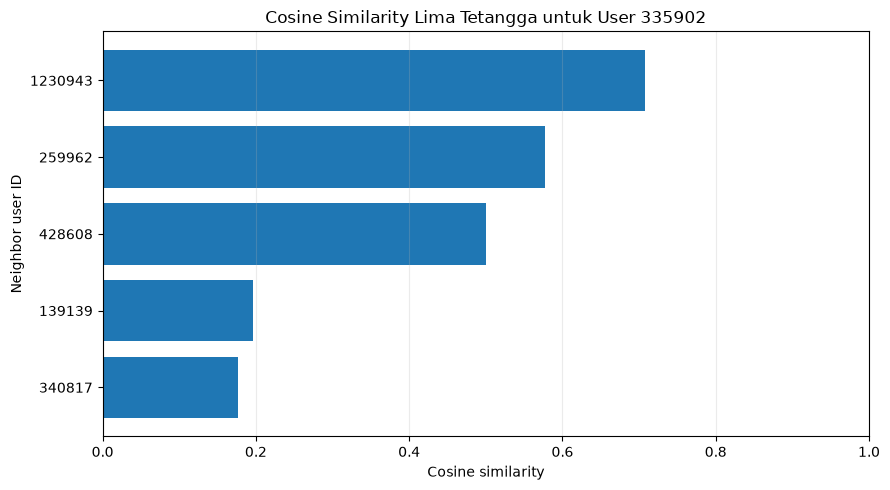

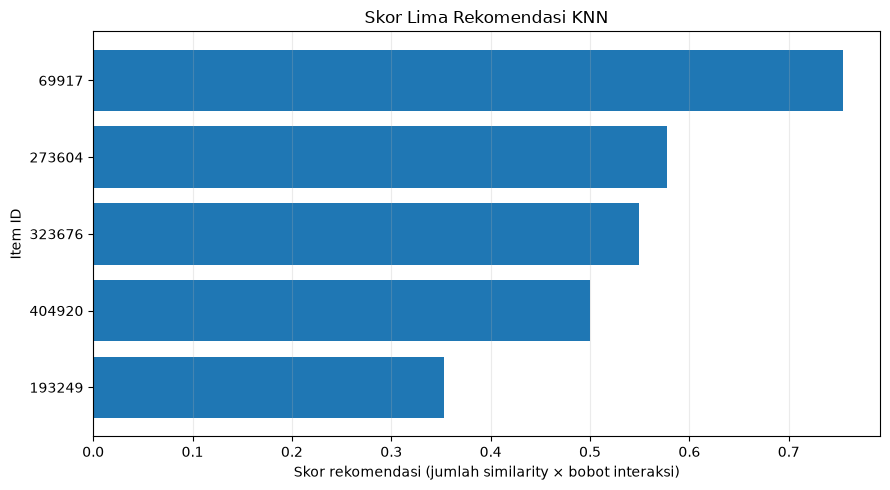

In [25]:
plt.figure(figsize=(9, 5))
neighbor_plot = neighbors_df.sort_values("cosine_similarity", ascending=True)
plt.barh(neighbor_plot["neighbor_user_id"].astype(str), neighbor_plot["cosine_similarity"])
plt.title(f"Cosine Similarity Lima Tetangga untuk User {int(user_ids[target])}")
plt.xlabel("Cosine similarity")
plt.ylabel("Neighbor user ID")
plt.xlim(0, 1.0)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "knn_neighbor_similarity.png", dpi=180)
plt.show()

plt.figure(figsize=(9, 5))
rec_plot = recommendations_df.sort_values("score", ascending=True)
plt.barh(rec_plot["item_id"].astype(str), rec_plot["score"])
plt.title("Skor Lima Rekomendasi KNN")
plt.xlabel("Skor rekomendasi (jumlah similarity × bobot interaksi)")
plt.ylabel("Item ID")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "knn_recommendation_scores.png", dpi=180)
plt.show()


In [26]:
top5_indices = chosen["ranked"][:5]
rel_flags = np.array([int(idx in relevant_set) for idx in top5_indices], dtype=int)
hit_at_5 = int(rel_flags.sum() > 0)
dcg = sum(rel / np.log2(rank + 2) for rank, rel in enumerate(rel_flags))
ideal_n = min(5, len(relevant_set))
idcg = sum(1.0 / np.log2(rank + 2) for rank in range(ideal_n))
ndcg_at_5 = dcg / idcg if idcg else 0.0

metrics = {
    "seed": SEED_KNN,
    "target_user_id": int(user_ids[target]),
    "k": K,
    "relevant_test_items": len(relevant_set),
    "relevant_in_top5": int(rel_flags.sum()),
    "Hit@5": hit_at_5,
    "NDCG@5": float(ndcg_at_5)
}
print("=== EVALUASI ===")
for k, v in metrics.items():
    print(f"{k}: {v}")
with open(DATA_DIR / "knn_metrics.txt", "w", encoding="utf-8") as f:
    for k, v in metrics.items():
        f.write(f"{k}: {v}\n")


=== EVALUASI ===
seed: 42
target_user_id: 335902
k: 5
relevant_test_items: 1
relevant_in_top5: 0
Hit@5: 0
NDCG@5: 0.0


### Visualisasi evaluasi dan interpretasi otomatis

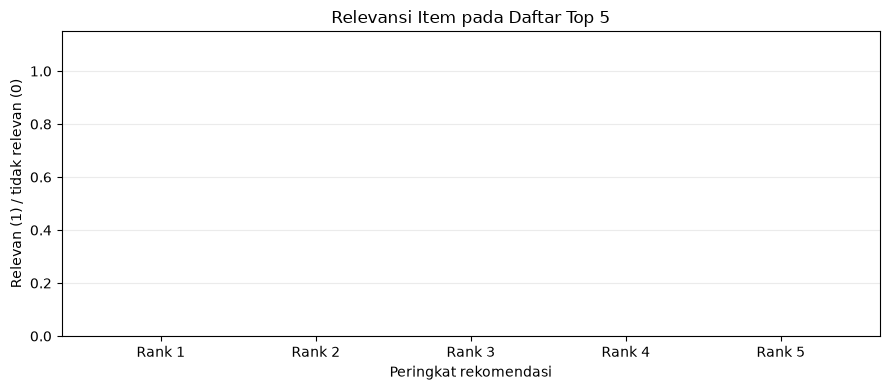

,Metrik,Nilai
0,Hit@5,0.0
1,NDCG@5,0.0


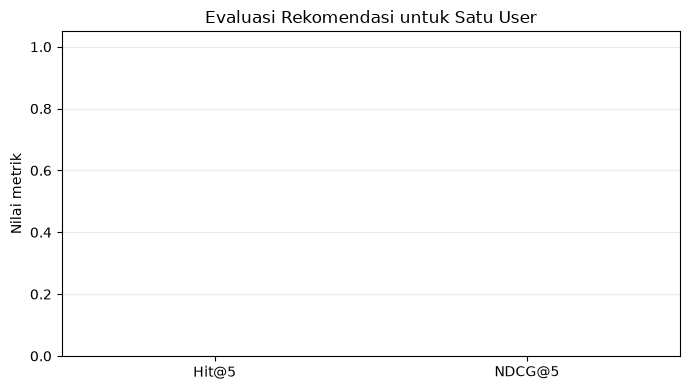

Interpretasi: tidak ada item relevan yang muncul pada Top 5; Hit@5 = 0.
NDCG@5 = 0.000000; metrik ini mempertimbangkan posisi item relevan di dalam ranking.


In [28]:
# Relevance by rank: 1 berarti relevan, 0 berarti tidak relevan.
rank_labels = [f"Rank {r}" for r in recommendations_df["rank"]]
relevance_by_rank = [
    int(np.where(item_ids == item_id)[0][0] in relevant_set)
    for item_id in recommendations_df["item_id"]
]

plt.figure(figsize=(9, 4))
plt.bar(rank_labels, relevance_by_rank)
plt.ylim(0, 1.15)
plt.title("Relevansi Item pada Daftar Top 5")
plt.xlabel("Peringkat rekomendasi")
plt.ylabel("Relevan (1) / tidak relevan (0)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "knn_relevance_by_rank.png", dpi=180)
plt.show()

metric_plot = pd.DataFrame({
    "Metrik": ["Hit@5", "NDCG@5"],
    "Nilai": [hit_at_5, ndcg_at_5]
})
display(metric_plot)

plt.figure(figsize=(7, 4))
plt.bar(metric_plot["Metrik"], metric_plot["Nilai"])
plt.ylim(0, 1.05)
plt.title("Evaluasi Rekomendasi untuk Satu User")
plt.ylabel("Nilai metrik")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "knn_metrics.png", dpi=180)
plt.show()

if hit_at_5 == 0:
    print("Interpretasi: tidak ada item relevan yang muncul pada Top 5; Hit@5 = 0.")
else:
    print("Interpretasi: setidaknya satu item relevan muncul pada Top 5; Hit@5 = 1.")
print(f"NDCG@5 = {ndcg_at_5:.6f}; metrik ini mempertimbangkan posisi item relevan di dalam ranking.")


In [ ]:
driver.close()
print("Koneksi Neo4j ditutup.")
